In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns

In [3]:
DATASET_PATH = '../Data/Raw/raw_dataset.csv'

def load_dataset(path: str):
    if not os.path.exists(path): return None
    return pd.read_csv(path)
    
dataset = load_dataset(DATASET_PATH)
dataset

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low


In [4]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [5]:
print(f'Dataset Contain {dataset.duplicated().sum()} Duplicated Row')

Dataset Contain 0 Duplicated Row


In [6]:
for column in dataset.select_dtypes(include='number').columns:
    quantiles = dataset[column].quantile([0.25, 0.75])

    q1 = quantiles[0.25]
    q3 = quantiles[0.75]

    iqr = q3 - q1
    mask = (dataset[column] < q1 - 1.5*iqr) | (dataset[column] > q3 + 1.5*iqr)
    display(dataset[['Student_ID', column]].iloc[mask])

,Student_ID,Age
209,STU0210,29
478,STU0479,28
1615,STU1616,28
1957,STU1958,28


,Student_ID,Year_of_Study


,Student_ID,Sleep_Hours
749,STU0750,3.6
1982,STU1983,3.3


,Student_ID,Study_Hours_Per_Week
340,STU0341,3.9
453,STU0454,3.2
519,STU0520,3.6
716,STU0717,38.3
866,STU0867,2.4
937,STU0938,37.5
1042,STU1043,2.7


,Student_ID,GPA
358,STU0359,3.60
448,STU0449,1.50
534,STU0535,3.66
881,STU0882,3.53
937,STU0938,3.64
1299,STU1300,3.57
1320,STU1321,3.51
1541,STU1542,1.60
1923,STU1924,3.51


,Student_ID,Social_Media_Hours
22,STU0023,2.4
180,STU0181,9.0
217,STU0218,2.8
268,STU0269,2.1
296,STU0297,9.4
328,STU0329,3.0
453,STU0454,10.0
470,STU0471,9.0
485,STU0486,2.9
747,STU0748,9.1


,Student_ID,Screen_Time_Hours
268,STU0269,3.4
485,STU0486,3.8
1030,STU1031,3.8
1169,STU1170,3.3
1466,STU1467,3.8
1487,STU1488,13.6
1754,STU1755,14.0


,Student_ID,Financial_Stress


,Student_ID,Family_Support


,Student_ID,Attendance_Rate
36,STU0037,61.1
277,STU0278,62.4
523,STU0524,62.5
539,STU0540,62.8
906,STU0907,62.5
1057,STU1058,63.2
1126,STU1127,65.4
1249,STU1250,65.3
1273,STU1274,54.4
1407,STU1408,61.8


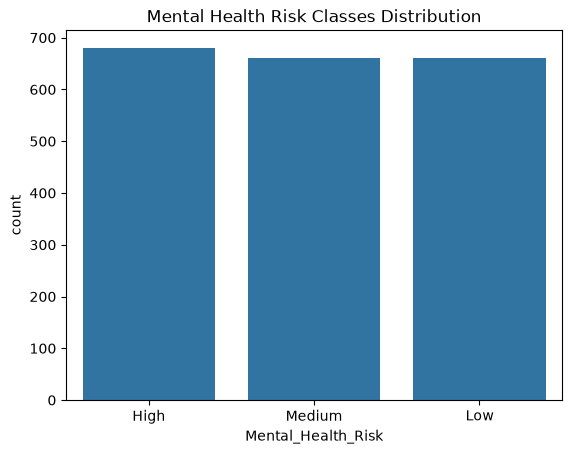

In [10]:
sns.barplot(dataset['Mental_Health_Risk'].value_counts())
plt.title('Mental Health Risk Classes Distribution')
plt.show()

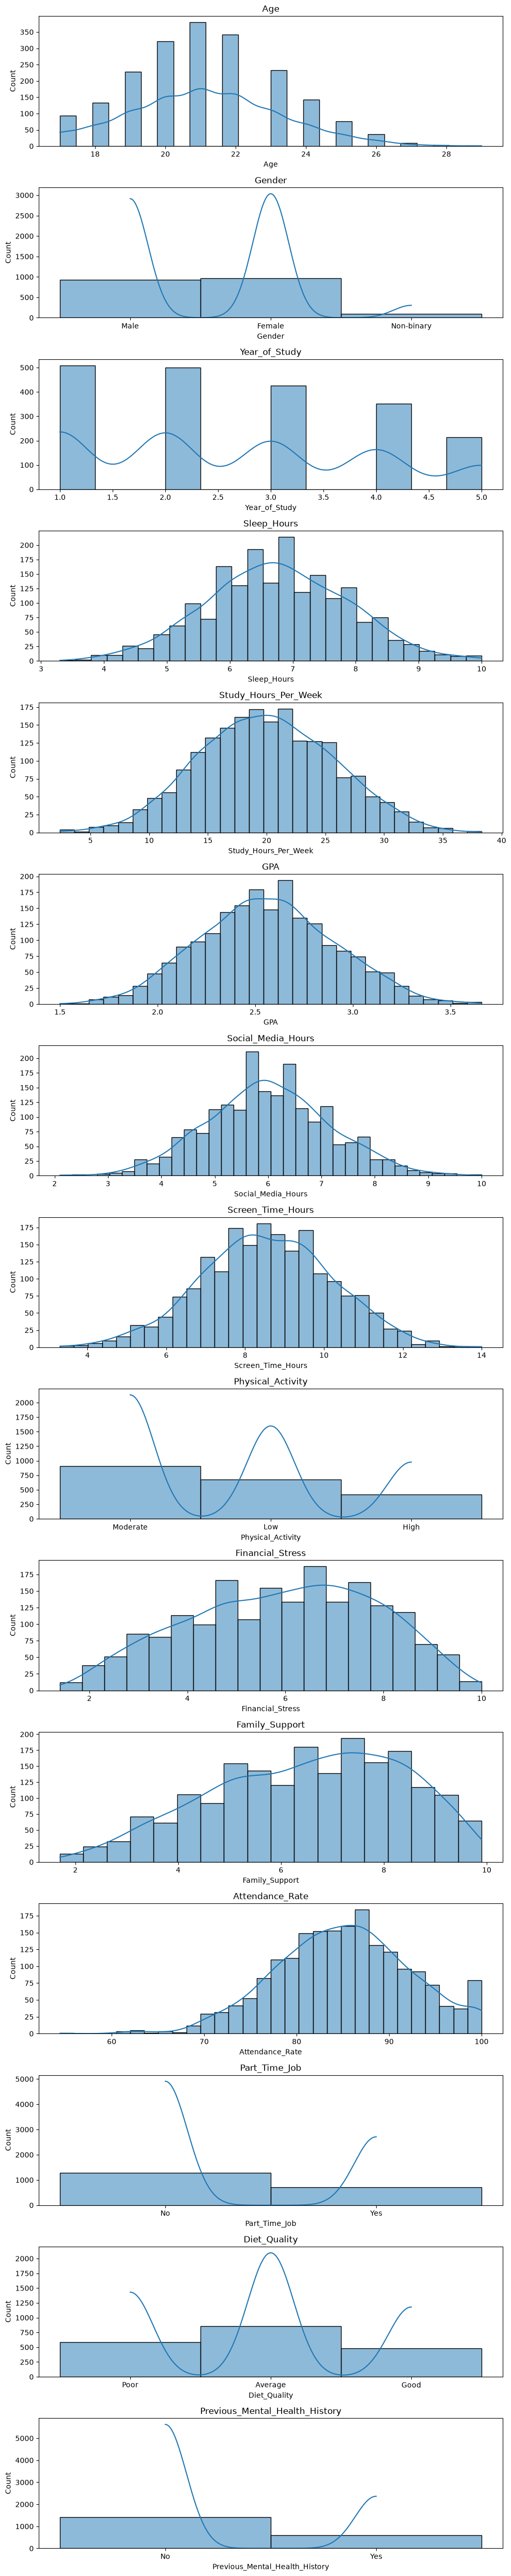

In [68]:
columns = dataset.drop(columns=['Student_ID', 'Mental_Health_Risk']).columns
fig, axes = plt.subplots(columns.shape[0], figsize=(10, 50))

for id, column in enumerate(columns):
    sns.histplot(dataset[column], ax=axes[id], kde=True)
    axes[id].set_title(column)
plt.tight_layout()
plt.show()

In [18]:
target = dataset['Mental_Health_Risk'].map({'Low': 0, 'Medium': 1, 'High': 2})
columns = dataset.select_dtypes(include='number').columns
num_copy = dataset[columns].corrwith(target)

In [31]:
# str_copy = dataset.select_dtypes(include='str')
str_copy = dataset.drop(columns='Student_ID')
str_copy['Mental_Health_Risk'] = str_copy['Mental_Health_Risk'].map({'Low': 0, 'Medium': 1, 'High': 2})
str_copy['Gender'] = str_copy['Gender'].map({'Male': 0, "Female": 1, "Non-binary": 2})
str_copy['Physical_Activity'] = str_copy['Physical_Activity'].map({'Low': 0, "Moderate": 1, "High": 2})
str_copy["Part_Time_Job"] = str_copy['Part_Time_Job'].map({'Yes': 0, "No": 1})
str_copy['Diet_Quality'] = str_copy['Diet_Quality'].map({'Poor': 0, "Good": 2, "Average": 1})
str_copy["Previous_Mental_Health_History"]= str_copy['Previous_Mental_Health_History'].map({'Yes': 0, "No": 1})

<Axes: >

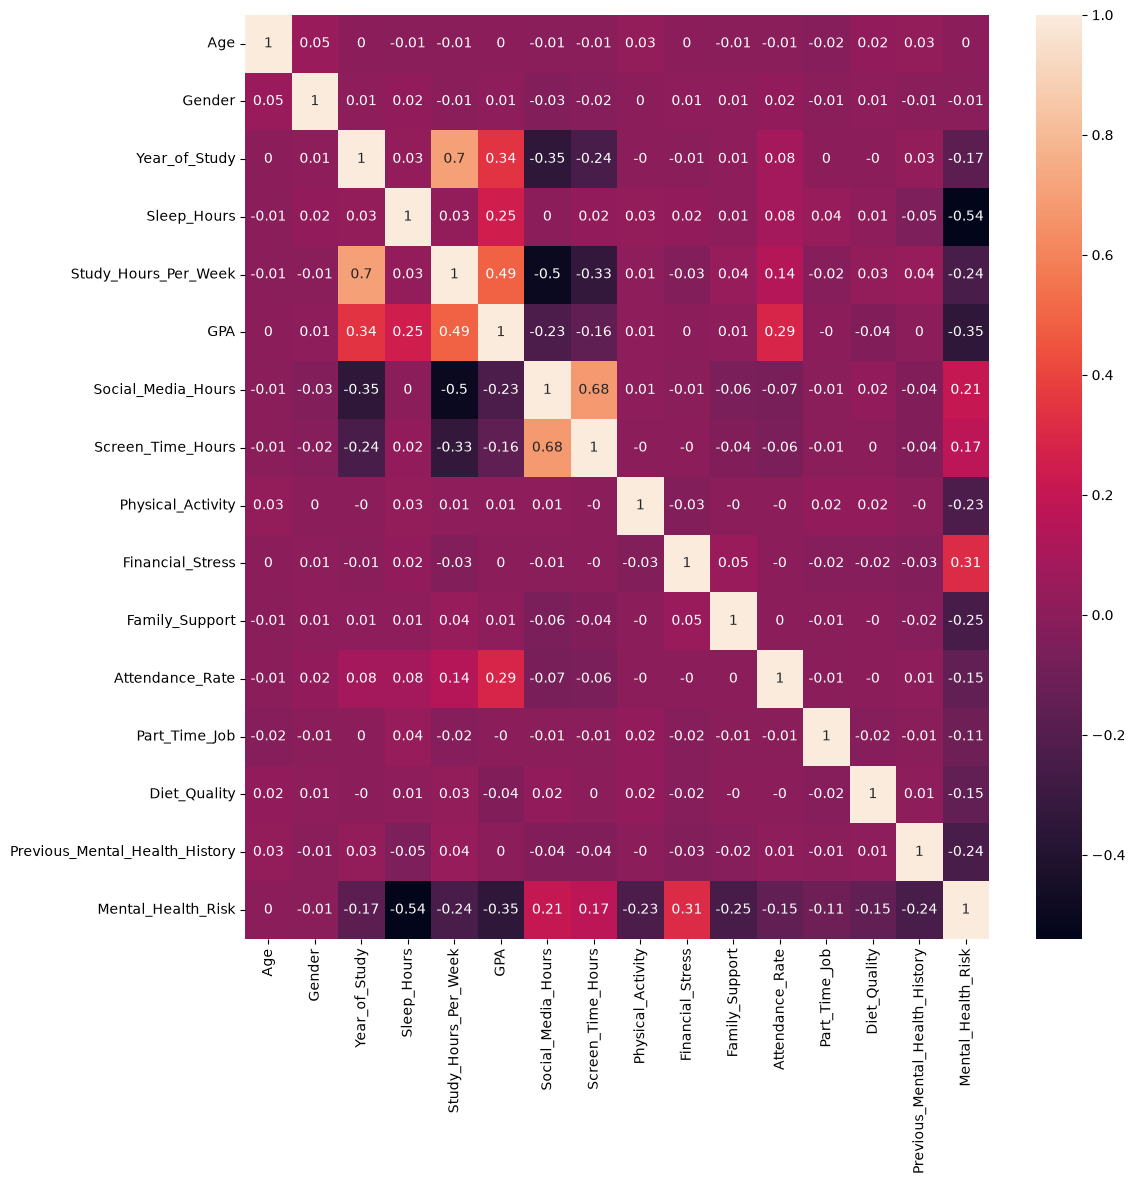

In [ ]:
vars_corr = str_copy.corr().round(2)

_, ax = plt.subplots(figsize=(12, 12))
sns.heatmap(vars_corr, annot=True, ax=ax)

In [60]:
risk_impact = vars_corr.iloc[:-1, -1:].abs().sort_values(by='Mental_Health_Risk', ascending=False)
risk_impact

,Mental_Health_Risk
Sleep_Hours,0.54
GPA,0.35
Financial_Stress,0.31
Family_Support,0.25
Previous_Mental_Health_History,0.24
Study_Hours_Per_Week,0.24
Physical_Activity,0.23
Social_Media_Hours,0.21
Screen_Time_Hours,0.17
Year_of_Study,0.17


In [67]:
def get_non_affecting_columns(dataset: pd.DataFrame, treshould = 0.1):
    mask = dataset['Mental_Health_Risk'] >= 0.1
    non_affecting_vars = dataset[~mask]
    print(f'{non_affecting_vars.index}')

get_non_affecting_columns(risk_impact)

Index(['Gender', 'Age'], dtype='str')
